In [2]:
import numpy as np
import time
from pympler import asizeof  # memory footprint
from scipy import sparse     # sparse matrix support
import csv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
def read_edges_with_counts_csv(filename, has_header=True):
    """
    Reads a CSV file containing edges and counts duplicates.

    Assumes first two columns are:
        source, target

    Edges are "harmonized" so as source < target

    Parameters
    ----------
    filename : str
    has_header : bool
        If True, skips first row.

    Returns
    -------
    list of (source, target, count)
    """

    edge_counts = {}

    with open(filename, newline='', encoding="utf-8") as f:
        reader = csv.reader(f)

        if has_header:
            next(reader, None)  # skip header

        for row in reader:
            source = row[0].strip()
            target = row[1].strip()

            if source < target:
                key = (source, target)
            else:
                key = (target, source)

            if key in edge_counts:
                edge_counts[key] += 1
            else:
                edge_counts[key] = 1

    return [(src, tgt, count) for (src, tgt), count in edge_counts.items()]

In [4]:
def build_adjacency_Matrix(edges, is_undirected=True):
    """
    Build dense adjacency matrix A with convention:
        A[i, j] = 1 if j -> i  (optionally one could use weights)
    For co-appearance (undirected), we add both directions with same weight.
    """
    names = sorted({u for u, _, _ in edges} | {v for _, v, _ in edges})
    idx = {name: i for i, name in enumerate(names)}
    n = len(names)
    A = np.zeros((n, n), dtype=np.float64)

    for src, tgt, count in edges:
        src_id = idx[src]
        tgt_id = idx[tgt]
        A[tgt_id, src_id] = 1  # src -> tgt
        if is_undirected:   # undirected -> two directed edges
            A[src_id, tgt_id] = 1  # tgt -> src
    
    return A, names

In [5]:
def build_transition_matrix(A, is_sparse=False):
    """
    Build the PageRank transition matrix M from adjacency matrix A.

    Convention:
        A[i][j] = 1 if node j links to node i (j -> i).
        Columns are sources; rows are destinations.

    Returns
    -------
    M : ndarray (n, n)
        Column-stochastic transition matrix where M[i][j] = Prob(move from j to i).
        Each column sums to 1.
        Dangling columns become uniform (1/n).
    """
    if is_sparse:
        M = sparse.csr_matrix(A, dtype=np.float64) # stores only non-zero values and their positions, so it is more memory efficient for sparse matrices
    else:
        # make it numpy array, and make sure it is copied
        M = np.asarray(A, copy=True, dtype=np.float64)
    
    n = M.shape[0] 
    # modified axis=1 insted of axis=0
    outdeg = np.asarray( M.sum(axis=0) ).ravel() # ravel to make it 1d array of shape (n,) i want array with n elements

    # non-dangling columns: normalize each column by its outdegree
    non_dangling = outdeg > 0
    M[:, non_dangling] = M[:, non_dangling] / outdeg[non_dangling]

    # dangling columns: uniform distribution
    dangling = outdeg == 0
    if np.any(dangling):
        M[:, dangling] = 1.0 / n

    return M, outdeg

In [6]:
def compute_pagerank(names, M, alpha=0.85, tol=1e-6, max_iter=100, is_sparse=False, verbose=False):
    """
    Compute PageRank

    Parameters
    ----------
    A : array_like (n, n)
        Dense adjacency with A[i, j] > 0 iff j -> i.
    alpha : float
        Damping factor.
    tol : float
        Convergence tolerance on L1 difference.
    max_iter : int
        Maximum iterations.
    verbose : bool
        Print L1 diff each iteration if True.

    Returns
    -------
    r : ndarray (n,)
        PageRank vector (sums to 1).
    iters : int
        Iterations performed.
    diff : float
        L1 difference from previous iteration.
    """
    # M, outdeg = build_transition_matrix(A, is_sparse)
    n = M.shape[0]

    # initial ranks
    pagerank = np.full(n, 1.0 / n, dtype=np.float64)

    for it in range(1, max_iter + 1):
        pagerank_next = alpha * (M @ pagerank) + (1.0 - alpha) * 1.0 / n
        pagerank_next = pagerank_next / pagerank_next.sum()  # normalize

        diff = np.abs(pagerank_next - pagerank).sum()  # L1
        if verbose:
            print(f"iter {it}: L1 diff = {diff:.3e}")

        if diff < tol:
            break

        pagerank = pagerank_next

    pairs = list(zip(names, pagerank))
    return pagerank_next, it, diff, pairs

In [7]:
RAW_EDGES = "hero-network.csv"
edges = read_edges_with_counts_csv(RAW_EDGES)
# edges removes already duplicated data
A, names = build_adjacency_Matrix(edges) # doents use the count 
M, outdeg = build_transition_matrix(A, is_sparse=True)  # precompute M for memory footprint

start = time.perf_counter()
     
r_sparse, iters, d, pairs = compute_pagerank(names, M, alpha=0.85, tol=1e-9, max_iter=200, is_sparse=True, verbose=False)

elapsed = time.perf_counter()-start

M, outdeg = build_transition_matrix(A, is_sparse=True)
footprint = asizeof.asizeof(M)

print (f"Elapsed time: {elapsed:.2f} sec.s")
print(f"Memory footprint {footprint/10**6:.2f} MB.")

print("PageRank:", r_sparse)
print("iters:", iters)
print("sum:", r_sparse.sum())


Elapsed time: 0.16 sec.s
Memory footprint 8.05 MB.
PageRank: [6.29994719e-05 2.85812118e-04 1.81257318e-04 ... 2.24083739e-04
 2.74567214e-04 9.78196648e-05]
iters: 64
sum: 1.0


The top ten ranked nodes are:

In [8]:
pairs_sorted = sorted(pairs, key=lambda x: x[1], reverse=True)
pairs_sorted[:10]

[('SPIDER-MAN/PETER PAR', np.float64(0.00529932252555056)),
 ('CAPTAIN AMERICA', np.float64(0.005125501982190033)),
 ('IRON MAN/TONY STARK', np.float64(0.004121239659110866)),
 ('WOLVERINE/LOGAN', np.float64(0.003863507201210941)),
 ('THING/BENJAMIN J. GR', np.float64(0.003684682045042992)),
 ('MR. FANTASTIC/REED R', np.float64(0.003576256074484838)),
 ('HUMAN TORCH/JOHNNY S', np.float64(0.0035121472821376264)),
 ('SCARLET WITCH/WANDA', np.float64(0.0032279669442586674)),
 ('THOR/DR. DONALD BLAK', np.float64(0.0032211855858739298)),
 ('BEAST/HENRY &HANK& P', np.float64(0.0031972190962931287))]

# 3rd Question



$\beta$ teleportation parameter

In [ ]:
beta_params = np.arange(0.0, 1.05, 0.05)

# Store all times and iterations for each beta
all_times = [[] for _ in beta_params]
all_iters = [[] for _ in beta_params]

all_ranks = [[] for _ in beta_params]

M, outdeg = build_transition_matrix(A, is_sparse=True)  # precompute M for memory footprint

for i, beta in enumerate(beta_params):
    start = time.perf_counter()
    r_sparse, iters, d, pairs = compute_pagerank(names, M, alpha=beta, tol=1e-9, max_iter=500, is_sparse=True, verbose=False)
    elapsed = time.perf_counter() - start

    pairs_sorted = sorted(pairs, key=lambda x: -x[1])
    all_ranks[i] = pairs_sorted

    all_times[i].append(elapsed)
    all_iters[i].append(iters)

In [10]:
# split for only top 10 names and ranks
top_k = 10
k_top_pairs = [[] for _ in beta_params]
for i in range(len(beta_params)):
    k_top_pairs[i] = all_ranks[i][:top_k]

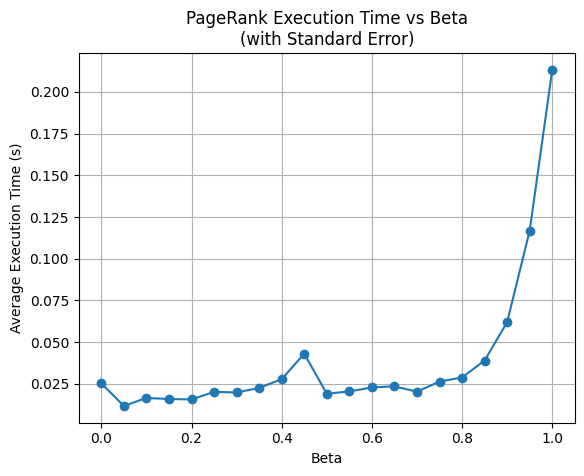

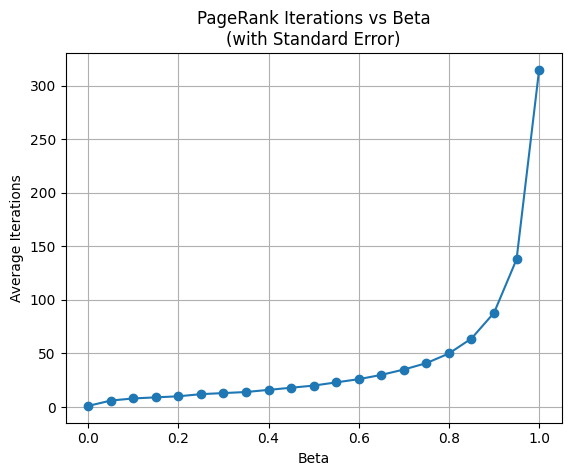

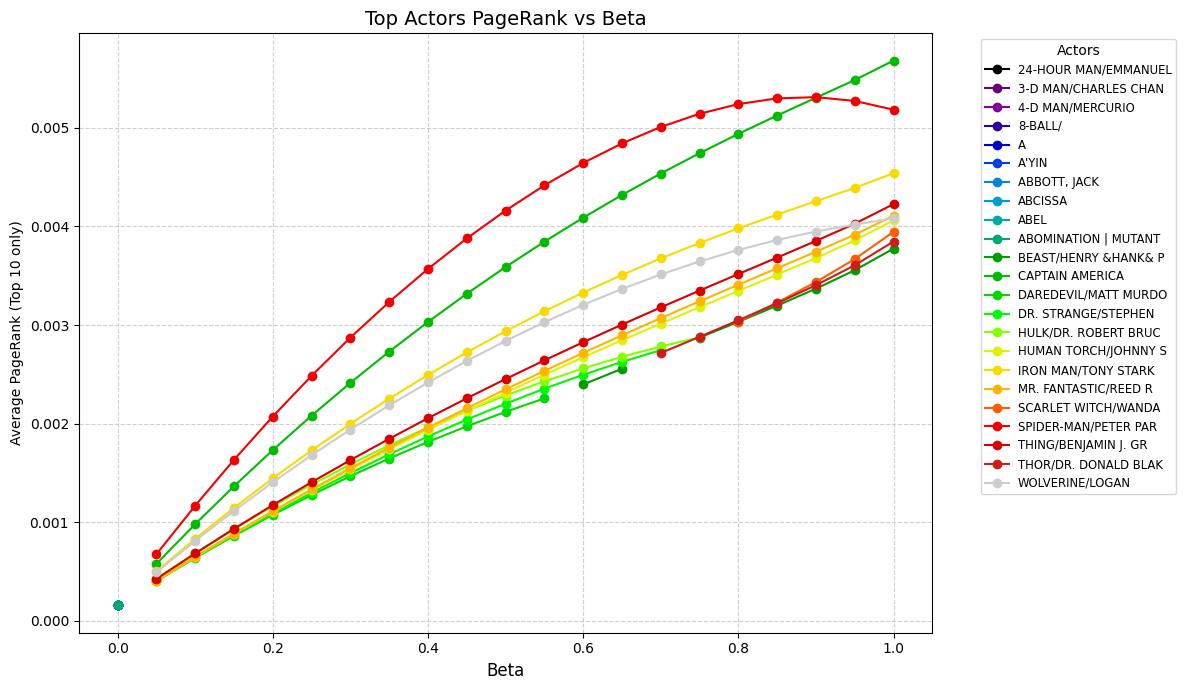

In [11]:
# plotting

means = [np.mean(times) for times in all_times]

mean_iters = [np.mean(iters) for iters in all_iters]

# Plot execution time
plt.errorbar(beta_params, means, fmt='-o', capsize=5)
plt.xlabel('Beta')
plt.ylabel('Average Execution Time (s)')
plt.title('PageRank Execution Time vs Beta\n(with Standard Error)')
plt.grid(True)
plt.show()

# Plot average iterations
plt.errorbar(beta_params, mean_iters, fmt='-o', capsize=5)
plt.xlabel('Beta')
plt.ylabel('Average Iterations')
plt.title('PageRank Iterations vs Beta\n(with Standard Error)')
plt.grid(True)
plt.show()

records = []
for i, beta in enumerate(beta_params):
    for name, score in k_top_pairs[i]:
        records.append({'Beta': beta, 'Name': name, 'Score': score})

df_plot = pd.DataFrame(records).pivot(index='Beta', columns='Name', values='Score')

ax = df_plot.plot(figsize=(12, 7), marker='o', cmap='nipy_spectral')
plt.xlabel('Beta', fontsize=12)
plt.ylabel('Average PageRank (Top 10 only)')
plt.title('Top Actors PageRank vs Beta', fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small', title="Actors")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

If you really like Jaccard, make it position-aware. Turn a list into a set of pairs (item, position) and take Jaccard on those. A softer variant gives partial credit to near matches by weighting each pair with exp(−lambda * |posA − posB|) and using a weighted Jaccard. 

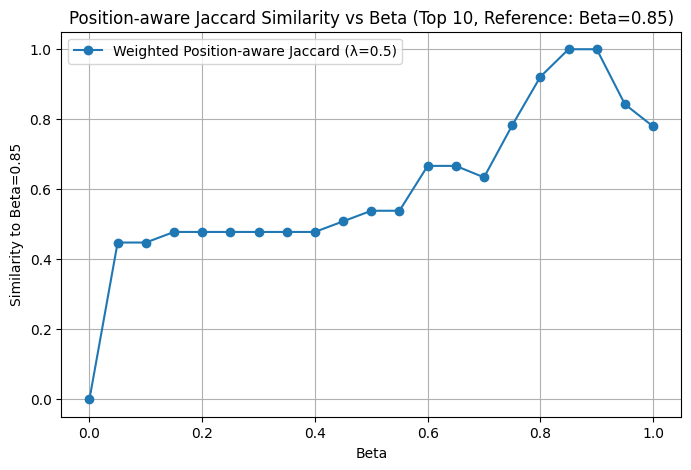

In [12]:
def weighted_position_jaccard(listA, listB, lambd=1.0):
    """
    Weighted position-aware Jaccard:
    For each item in both lists, gives partial credit to near matches by weighting with exp(-lambda * |posA - posB|).
    """
    setA = {item: i for i, item in enumerate(listA)}
    setB = {item: i for i, item in enumerate(listB)}
    items = set(setA.keys()) | set(setB.keys())
    numer = 0.0
    denom = 0.0
    for item in items:
        inA = item in setA
        inB = item in setB
        if inA and inB:
            posA = setA[item]
            posB = setB[item]
            w = np.exp(-lambd * abs(posA - posB))
            numer += w
            denom += 1.0
        else:
            denom += 1.0
    return numer / denom if denom > 0 else 0

# Compare each beta with beta=0.85 (index 17) for all runs
ref_index = 17  
lambd = 0.5

weighted_scores = []
for i in range(len(beta_params)):
    listA = [name for name, _ in k_top_pairs[i]]
    listB = [name for name, _ in k_top_pairs[ref_index]]
    weighted_scores.append(weighted_position_jaccard(listA, listB, lambd=lambd))

plt.figure(figsize=(8, 5))
plt.plot(beta_params, weighted_scores, marker='o', label=f'Weighted Position-aware Jaccard (λ={lambd})')
plt.xlabel('Beta')
plt.ylabel('Similarity to Beta=0.85')
plt.title('Position-aware Jaccard Similarity vs Beta (Top 10, Reference: Beta=0.85)')
plt.legend()
plt.grid(True)
plt.show()

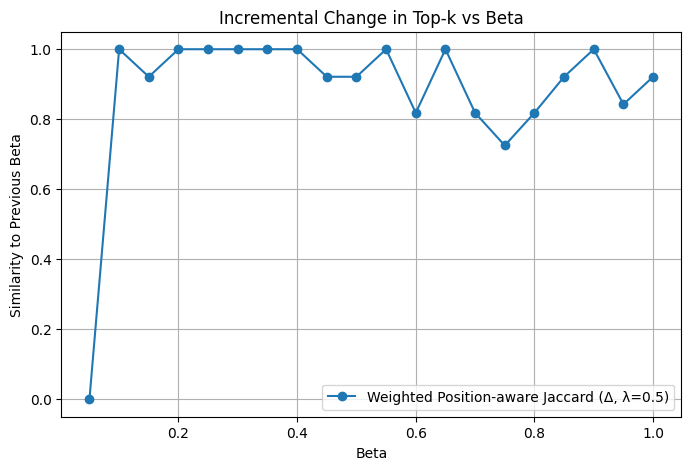

In [13]:
# Compare each beta's top-k list to the previous beta's list
lambd = 0.5

weighted_scores = []
for i in range(1, len(beta_params)):
    listA = [name for name, _ in k_top_pairs[i]]
    listB = [name for name, _ in k_top_pairs[i-1]]
    weighted_scores.append(weighted_position_jaccard(listA, listB, lambd=lambd))

plt.figure(figsize=(8, 5))
plt.plot(beta_params[1:], weighted_scores, marker='o', label=f'Weighted Position-aware Jaccard (Δ, λ={lambd})')
plt.xlabel('Beta')
plt.ylabel('Similarity to Previous Beta')
plt.title('Incremental Change in Top-k vs Beta')
plt.legend()
plt.grid(True)
plt.show()